# Q1: K-nearest neighbours

Classify handwritten digits 4 and 9. To run, place the supplied `knn-dataset` folder beside this notebook. Required packages: NumPy, pandas, Matplotlib and scikit-learn.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})
print('Python:', sys.version.split()[0])
print('NumPy:', np.__version__, '| pandas:', pd.__version__, '| scikit-learn:', sklearn.__version__)

from sklearn.model_selection import StratifiedKFold

Python: 3.12.14
NumPy: 2.3.5 | pandas: 2.2.3 | scikit-learn: 1.9.1


## Training data

Each image has 64 features with values from 0 to 16. The last column is the label and is excluded from distance calculations. No scaling is applied because all features use the same units.

Training shape: (904, 64)
Label counts: {4: 465, 9: 439}


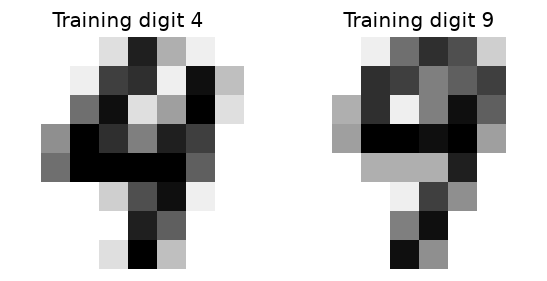

In [2]:
train = pd.read_csv(Path('knn-dataset') / 'train.csv')
assert train.shape == (904, 65)
assert not train.isna().any().any()
X_train = train.drop(columns='label').to_numpy(dtype=float)
y_train = train['label'].to_numpy(dtype=int)
assert set(y_train) == {4, 9}
assert np.all((X_train >= 0) & (X_train <= 16))
print('Training shape:', X_train.shape)
print('Label counts:', train['label'].value_counts().sort_index().to_dict())
fig, axes = plt.subplots(1, 2, figsize=(5, 2.4))
for ax, digit in zip(axes, [4, 9]):
    idx = np.flatnonzero(y_train == digit)[0]
    ax.imshow(X_train[idx].reshape(8, 8), cmap='gray_r', vmin=0, vmax=16)
    ax.set_title(f'Training digit {digit}')
    ax.axis('off')
plt.tight_layout()
plt.show()

## Distance and prediction

Euclidean distance is $d(x,z)=\sqrt{\sum_j(x_j-z_j)^2}$. The prediction is the most frequent label among the k closest training examples. Tied votes choose 4, and equal distances keep the training-row order. Both distance and voting are implemented below.

In [3]:
def euclidean_distance(x, reference):
    differences = np.asarray(reference, dtype=float) - np.asarray(x, dtype=float)
    return np.sqrt(np.sum(differences ** 2, axis=-1))

def majority_vote(labels):
    counts = {}
    for label in labels:
        label = int(label)
        counts[label] = counts.get(label, 0) + 1
    if not counts:
        raise ValueError('At least one neighbour is required.')
    return min(counts, key=lambda label: (-counts[label], label))

def neighbour_order(x, reference):
    distances = euclidean_distance(x, reference)
    return np.argsort(distances, kind='stable')

def knn_predict(reference, labels, queries, k):
    if not 1 <= k <= len(reference):
        raise ValueError('k must be between 1 and the number of reference rows.')
    return np.array([
        majority_vote(labels[neighbour_order(x, reference)[:k]])
        for x in queries
    ])

assert euclidean_distance([0, 0], [3, 4]) == 5
assert majority_vote([4, 9, 4]) == 4
assert majority_vote([9, 4]) == 4
assert knn_predict(np.array([[0., 0.], [10., 10.]]), np.array([4, 9]),
                   np.array([[1., 1.], [9., 9.]]), 1).tolist() == [4, 9]
print('Distance, vote, tie and prediction checks passed.')

Distance, vote, tie and prediction checks passed.


## Select k with 10-fold cross-validation

Use stratified folds with shuffling and random_state=42. Evaluate every k from 1 to 30 on the same folds and average the ten accuracies. Distances are reused across k values. If scores tie, select the smallest k. The test set is not used in this step.

 k mean_cv_accuracy
 1         0.994469
 2         0.990049
 3         0.997790
 4         0.996679
 5         0.996679
 6         0.996679
 7         0.994481
 8         0.994481
 9         0.994481
10         0.994481
11         0.994481
12         0.995580
13         0.994481
14         0.994481
15         0.993382
16         0.993382
17         0.993382
18         0.993382
19         0.993382
20         0.993382
21         0.993382
22         0.993382
23         0.993382
24         0.993382
25         0.993382
26         0.993382
27         0.993382
28         0.993382
29         0.993382
30         0.993382
Best k: 3; mean CV accuracy: 99.778999%
Tied best k values: [3]


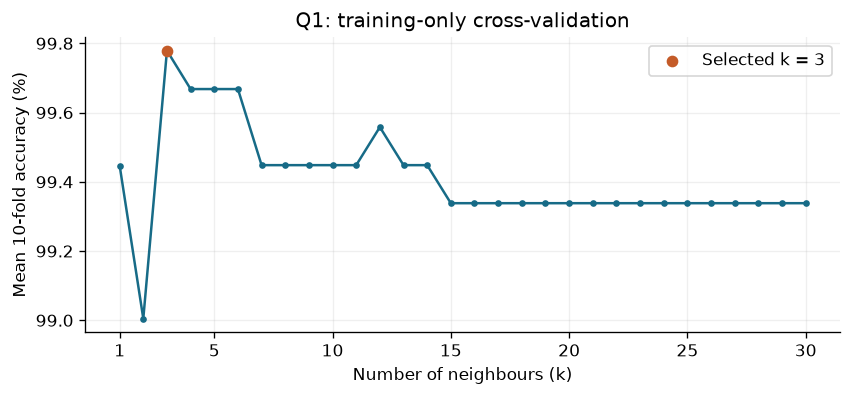

In [4]:
k_values = np.arange(1, 31)
folds = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
fold_scores = np.zeros((10, len(k_values)))
seen = np.zeros(len(y_train), dtype=int)
for fold, (fit_idx, val_idx) in enumerate(folds.split(X_train, y_train)):
    assert not np.intersect1d(fit_idx, val_idx).size
    seen[val_idx] += 1
    reference, labels = X_train[fit_idx], y_train[fit_idx]
    predictions = np.empty((len(val_idx), len(k_values)), dtype=int)
    for row, x in enumerate(X_train[val_idx]):
        ordered_labels = labels[neighbour_order(x, reference)[:30]]
        for col, k in enumerate(k_values):
            predictions[row, col] = majority_vote(ordered_labels[:k])
    fold_scores[fold] = np.mean(predictions == y_train[val_idx, None], axis=0)
assert np.all(seen == 1)
mean_scores = fold_scores.mean(axis=0)
best_index = int(np.argmax(mean_scores))  # First maximum: smallest k.
best_k = int(k_values[best_index])
cv_results = pd.DataFrame({'k': k_values, 'mean_cv_accuracy': mean_scores})
print(cv_results.to_string(index=False, formatters={'mean_cv_accuracy': '{:.6f}'.format}))
print(f'Best k: {best_k}; mean CV accuracy: {mean_scores[best_index]:.6%}')
print('Tied best k values:', k_values[mean_scores == mean_scores[best_index]].tolist())
fig, ax = plt.subplots(figsize=(7.2, 3.4))
ax.plot(k_values, mean_scores * 100, marker='o', markersize=3, color='#176b87')
ax.scatter([best_k], [mean_scores[best_index] * 100], color='#c45b28', zorder=3, label=f'Selected k = {best_k}')
ax.set(xlabel='Number of neighbours (k)', ylabel='Mean 10-fold accuracy (%)', title='Q1: training-only cross-validation')
ax.set_xticks([1, 5, 10, 15, 20, 25, 30])
ax.grid(alpha=.2)
ax.legend()
plt.tight_layout()
plt.show()

## Test the selected k

Use all 904 training examples as the reference set. Load the test data and evaluate the selected k once.

In [5]:
test = pd.read_csv(Path('knn-dataset') / 'test.csv')
assert test.shape == (226, 65)
assert list(test.columns) == list(train.columns)
assert not test.isna().any().any()
X_test = test.drop(columns='label').to_numpy(dtype=float)
y_test = test['label'].to_numpy(dtype=int)
test_predictions = knn_predict(X_train, y_train, X_test, best_k)
test_correct = int(np.sum(test_predictions == y_test))
test_accuracy = test_correct / len(y_test)
print(f'Selected k: {best_k}')
print(f'Mean cross-validation accuracy: {mean_scores[best_index]:.6%}')
print(f'Final test accuracy: {test_accuracy:.6%} ({test_correct}/{len(y_test)})')

Selected k: 3
Mean cross-validation accuracy: 99.778999%
Final test accuracy: 99.557522% (225/226)


## Results

The best k is 3, with mean cross-validation accuracy of 99.7790%. Test accuracy is 99.5575% (225 of 226 correct). These results apply to the two classes, 4 and 9.

Data: supplied digit training and test CSV files.